Maximum Range: 40.77467482041533 m (Angle: 45.04249225740834 degrees)
Maximum Height: 20.387264032822113 m (Angle: 89.87579631574097 degrees)


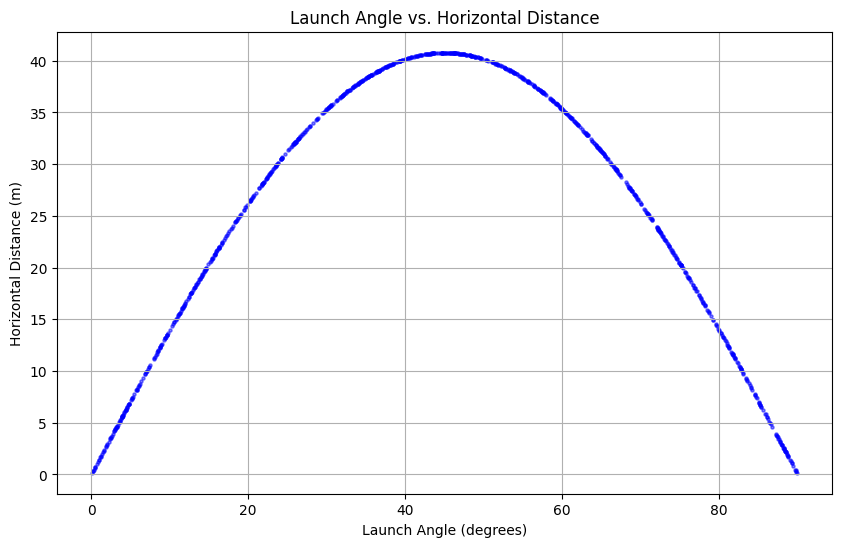

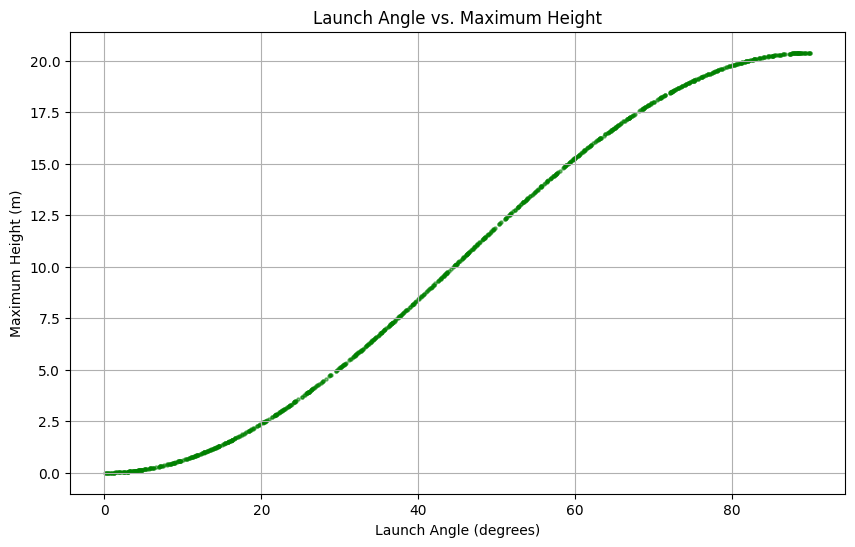

In [3]:

import numpy as np
import matplotlib.pyplot as plt

def projectile_motion(theta, u, g=9.81):
    """
    Calculate projectile motion given launch angle and initial velocity.
    Returns the horizontal distance traveled, maximum height, and time of flight.
    """
    theta_rad = np.radians(theta)
    time_of_flight = 2 * u * np.sin(theta_rad) / g
    horizontal_distance = u * np.cos(theta_rad) * time_of_flight
    max_height = (u * np.sin(theta_rad))**2 / (2 * g)
    return horizontal_distance, max_height, time_of_flight

def monte_carlo_simulation(num_trials, u, g=9.81):
    """
    Perform Monte Carlo simulation for projectile motion with random launch angles.
    Returns arrays of horizontal distances, maximum heights, for each trial.
    """
    distances = []
    max_heights = []
    launch_angles = []
    for i in range(num_trials):
        # Generate random launch angle between 0 and 90 degrees
        theta = np.random.uniform(0, 90)
        distance, max_height,time_of_flight = projectile_motion(theta, u, g)
        distances.append(distance)
        max_heights.append(max_height)
        launch_angles.append(theta)
    return np.array(distances), np.array(max_heights), np.array(launch_angles)

# Parameters
num_trials = 1000
u = 20  #initial velocity in m/s

# Perform simulation
distances, max_heights,launch_angles = monte_carlo_simulation(num_trials, u)

# Calculate max range and height
max_range = np.max(distances)
max_height = np.max(max_heights)

# Find the index of the angle for max range and max height
index_max_range = np.argmax(distances)
index_max_height = np.argmax(max_heights)

#Get launch angles for max range and max height
angle_max_range = launch_angles[index_max_range]
angle_max_height = launch_angles[index_max_height]

print("Maximum Range:", max_range, "m (Angle:", angle_max_range, "degrees)")
print("Maximum Height:", max_height, "m (Angle:", angle_max_height, "degrees)")

plt.figure(figsize=(10, 6))

#Plot angles vs horizontal distance
plt.scatter(launch_angles, distances, s=5, color='blue', alpha=0.5)
plt.xlabel('Launch Angle (degrees)')
plt.ylabel('Horizontal Distance (m)')
plt.title('Launch Angle vs. Horizontal Distance')
plt.grid(True)

plt.figure(figsize=(10, 6))

#Plot angles vs vertical distance
plt.scatter(launch_angles, max_heights, s=5, color='green', alpha=0.5)
plt.xlabel('Launch Angle (degrees)')
plt.ylabel('Maximum Height (m)')
plt.title('Launch Angle vs. Maximum Height')
plt.grid(True)

plt.show()